# 04 · Three versions of 30 m segments from the same photons: current, check, and new

**Question:** for the same ATL03 v007 photons in the G-LiHT tiles, how do the 30 m heights built from the **reclassified photon
classes** differ from the **ATL08 · PhoREAL (today) segments** in our training files, and how much of that difference comes from the
photon classification rather than from how the photons are binned into 30 m segments?

- **ATL08 · PhoREAL (today):** SlideRule PhoREAL on the ATL08 v007 photon classes, with the settings of
  `process_atl08_boreal.py` (1 m vertical bins, `geoloc=center`, ABoVE top-of-canopy classifier).
- **ATL08 · our binning (control):** our binning (`segment_metrics`) of the same ATL08 v007 photon classes, heights above a
  ground drawn through the ATL08 ground photons.
- **reclassified (this config):** our binning of the reclassified photon classes, with the short-vegetation guard.

Current vs check isolates the binning; check vs new isolates the classification; current vs new is what would change in training.

### Terms used in this notebook (same in every notebook of this series)

**Photons and their classes**
| Term | What it is |
|---|---|
| **ATL03 v007 photons** | Every photon ICESat-2 recorded (signal and solar background), with height and position. Nothing is classified yet. "v007" is the NASA data release; every version below uses release 007. |
| **ATL08 v007 photon classes** | NASA's labels for those photons (noise / ground / canopy / top of canopy), from the ATL08 product. Our current training data are built from these. |
| **Reclassified photon classes** | Our own labels for the **same** photons, from `lib/icesat2_photon_lib.py: reclassify` with the thresholds of one config version (`config/atl03_reclass_v0.N.yaml`). |
| **Reference photon labels** | Labels from airborne lidar (G-LiHT) or UAV surface models: a photon at the reference ground is ground, between ground and the reference canopy top is canopy, far above or below is noise. Treated as the truth. |

**30 m segments: a name says whose photon classes, then who cut them into 30 m segments and computed the heights**
| | binned by SlideRule PhoREAL | binned by our code (`segment_metrics`) |
|---|---|---|
| **ATL08 v007 photon classes** | **ATL08 · PhoREAL (today)**: what our training files contain today | **ATL08 · our binning (control)**: same classes, our binning; any difference from "today" is binning, not classification |
| **reclassified photon classes** | (not made) | **reclassified v0.N**: the candidate product, config v0.N |

Comparing **today** with **reclassified v0.N** is the result that matters; the **control** shows how much of that difference
comes from binning alone. Earlier notebooks and LOG entries called these "current v7 30 m", "ATL08 classes → our 30 m (check)"
and "reclassified photons → our 30 m (new)".

`h_canopy` = 98th percentile of canopy-photon heights above the ground in a 30 m segment (as in ATL08).
**Reference height** of a segment = 98th percentile of the 1 m reference canopy height model (G-LiHT or UAV) inside the segment's footprint (30 m along track × 11 m).

In [1]:
import sys, os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)

REPO = Path.cwd().resolve().parents[1]          # notebooks/atl03_reclass -> repo root
sys.path.insert(0, str(REPO / "lib"))
import icesat2_photon_lib as ipl, reference_lib as ref, validation_lib as val, plot_style as ps
ps.apply()   # shared figure style; vegetation-height colormap ps.HEIGHT_CMAP; ESRI Light Gray basemap ps.add_basemap

cfg = ipl.load_config(REPO / "config" / "atl03_reclass_v0.6.yaml")   # profile auto: 'maap' on MAAP ADE, else 'adapt'
WORK = Path(cfg["paths"]["work_dir"]); WORK.mkdir(parents=True, exist_ok=True)   # shared inputs: downloads, fetched photons, inventories
RUN = WORK / "runs" / f"v{cfg['version']}"; RUN.mkdir(parents=True, exist_ok=True)   # everything that depends on the config version
FIG = RUN / "figures"; FIG.mkdir(exist_ok=True)
print("profile:", cfg["profile"], "| config", cfg["version"], cfg["config_sha1"], "| work_dir:", WORK, "| run_dir:", RUN)
print(json.dumps(ipl.provenance(cfg), indent=1))

profile: adapt | config 0.6 40e8f82a4112 | work_dir: /explore/nobackup/people/pmontesa/atl03_reclass | run_dir: /explore/nobackup/people/pmontesa/atl03_reclass/runs/v0.6


{
 "repo": "circumpolar_boreal_trends",
 "git_commit": "0cecd4e",
 "git_dirty_lib_or_config": true,
 "config_version": "0.6",
 "config_sha1": "40e8f82a4112",
 "sliderule_client": "5.6.3",
 "processed_utc": "2026-10-18T04:32:31"
}


## Build the three versions of 30 m segments for each G-LiHT tile

**Input:** the photons with both classifications (notebook 03) and the PhoREAL segments downloaded in notebook 02.

**What happens:**
- **reclassified (this config):** `segment_metrics` on `class_new` / `relief_new`, including the short-vegetation guard.
- **ATL08 · our binning (control):** `segment_metrics` on `atl08_class` / `relief_atl08`.
- **ATL08 · PhoREAL (today):** read from `phoreal.parquet`.
- The three are matched by track and position (nearest within 20 m). Each segment also gets the share of its photons in
  disturbed forest (notebook 02, step 6).

**Output:** `segments/tile_<n>_segments.parquet`: one row per new segment, with `h_canopy` (reclassified), `h_canopy_atl08` (control) and
`h_canopy_phoreal` (current).

In [2]:
GL = WORK / "glihit"; OUT = RUN / "segments"; OUT.mkdir(exist_ok=True)
ph = gpd.read_parquet(RUN / "reclass" / "glihit_photons_reclassified.parquet")
tiles = sorted(ph.tile_num.unique())
segs = []
for t in tiles:
    fn = OUT / f"tile_{t}_segments.parquet"
    if fn.exists():
        segs.append(gpd.read_parquet(fn)); continue
    p = ph[ph.tile_num == t]
    s_new = ipl.segment_metrics(p, cfg, "class_new", "relief_new", "new")
    s_nat = ipl.segment_metrics(p, cfg, "atl08_class", "relief_atl08", "atl08")
    keep = ["h_canopy", "n_canopy", "n_ground", "Ev", "Eg"]
    s = ipl.match_segments(s_new, s_nat[["track_id", "geometry"] + keep], keep, suffix="_atl08")
    prf = GL / f"tile_{t}" / "phoreal.parquet"
    if prf.exists():
        pr = gpd.read_parquet(prf).to_crs(4326)
        s = ipl.match_segments(s, pr[["track_id", "geometry", "h_canopy", "canopy_openness"]], ["h_canopy", "canopy_openness"], suffix="_phoreal")
    # share of disturbed photons per segment (from notebook 02)
    p = p.assign(seg=np.floor(p.x_atc / cfg["segments"]["length_m"]).astype(int))
    d = p.groupby(["track_id", "seg"]).agg(disturbed_frac=("disturbed", "mean"), region=("region", "first"), als_year=("als_year", "first")).reset_index()
    s = s.merge(d, on=["track_id", "seg"], how="left")
    s["tile_num"] = t
    ipl.write_parquet(s, fn, ipl.provenance(cfg, tile_num=int(t)))
    segs.append(s)
segs = gpd.GeoDataFrame(pd.concat(segs, ignore_index=True), crs=4326)
print(len(segs), "segments;", segs.groupby("region").size().to_dict())

36681 segments; {'Interior': 23104, 'Kenai': 13577}


## Check: does our 30 m binning reproduce PhoREAL?

Both axes use the **ATL08 v007 photon classes**; only the binning differs: **ATL08 · our binning (control)** (y) vs
**ATL08 · PhoREAL (today)** (x). If they agree, any difference between "current" and "new" below comes
from the photon classification. If they don't, part of it comes from the binning and has to be accounted for (in notebook 01
our binning gave higher heights than PhoREAL from the same classes).

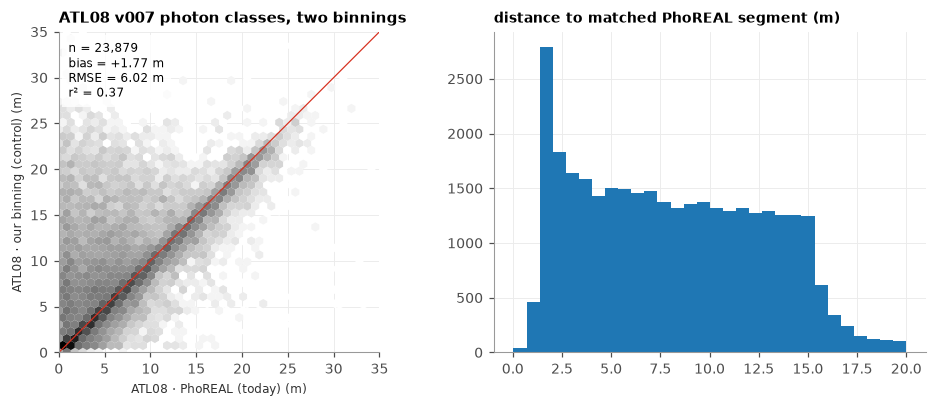

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
val.plot_scatter(axes[0], segs.h_canopy_atl08, segs.h_canopy_phoreal, "ATL08 v007 photon classes, two binnings", lim=35)
axes[0].set_xlabel(val.LABEL_CURRENT + " (m)", fontsize=8); axes[0].set_ylabel(val.LABEL_CHECK + " (m)", fontsize=8)
axes[1].hist(segs.match_dist_m.dropna(), bins=30); axes[1].set_title("distance to matched PhoREAL segment (m)", loc="left", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "04_binning_check.png", dpi=150)

## New vs current: how the reclassified 30 m heights differ from what our training files contain

Left: **reclassified (this config)** vs **ATL08 · PhoREAL (today)** for the same segments.
Middle: the difference (new − current) by current height. Right: height distributions per region. This is a comparison of
the two products, not a validation; notebook 05 compares both with G-LiHT.

,segments,short_veg_flag,matched_to_phoreal
region,,,
Interior,23104,0.250,0.923
Kenai,13577,0.294,0.866


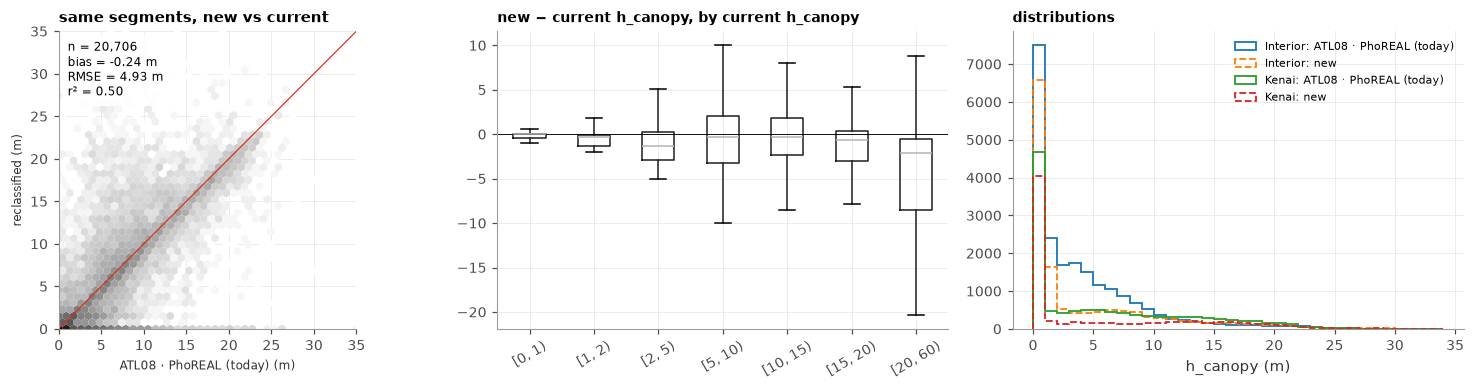

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
val.plot_scatter(axes[0], segs.h_canopy, segs.h_canopy_phoreal, "same segments, new vs current", lim=35)
axes[0].set_xlabel(val.LABEL_CURRENT + " (m)", fontsize=8); axes[0].set_ylabel(val.LABEL_NEW + " (m)", fontsize=8)
d = segs.h_canopy - segs.h_canopy_phoreal
b = pd.cut(segs.h_canopy_phoreal, [0, 1, 2, 5, 10, 15, 20, 60], right=False)
segs.assign(diff=d, bin=b).boxplot(column="diff", by="bin", ax=axes[1], showfliers=False, rot=30)
axes[1].axhline(0, c="k", lw=0.6); axes[1].set_title("new − current h_canopy, by current h_canopy", loc="left", fontsize=9); axes[1].set_xlabel(""); fig.suptitle("")
for reg, g in segs.groupby("region"):
    axes[2].hist(g.h_canopy_phoreal.dropna(), bins=np.arange(0, 35, 1), histtype="step", lw=1.2, label=f"{reg}: ATL08 · PhoREAL (today)")
    axes[2].hist(g.h_canopy.dropna(), bins=np.arange(0, 35, 1), histtype="step", lw=1.2, ls="--", label=f"{reg}: new")
axes[2].legend(fontsize=7); axes[2].set_xlabel("h_canopy (m)"); axes[2].set_title("distributions", loc="left", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "04_new_vs_current.png", dpi=150)
pd.DataFrame({"segments": segs.groupby("region").size(), "short_veg_flag": segs.groupby("region").short_veg_flag.mean().round(3),
              "matched_to_phoreal": segs.groupby("region").h_canopy_phoreal.apply(lambda v: v.notna().mean()).round(3)})

## Results (config v0.6, 18 October 2026)

- **36,681 segments** on the four G-LiHT tiles (Interior 23,104, Kenai 13,577); 87–92 % match an ATL08 · PhoREAL (today)
  segment on the same track.
- **Binning check:** the control (ATL08 classes, our binning) reads higher than today in short vegetation, because PhoREAL's
  top-of-canopy handling removes scattered high photons that our binning keeps (notebook 05: control +2.1 m overall vs today
  0.0 m). The improvements of the reclassified versions therefore come from the photon labels, not from our binning
  (notebook 11, appendix 1).
- **Reclassified vs today:** 25 % (Interior) and 29 % (Kenai) of reclassified segments are 0 m (vegetation would have been
  seen and was not); today's heights over those segments are mostly the false shrub heights of notebooks 01 and 05.